In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage import io, data, img_as_float
from skimage.filters import sobel, sobel_h, sobel_v, roberts
from skimage.filters import threshold_otsu, laplace

# Point detection

array([[ 96,  95,  93, ..., 102, 102, 103],
       [ 95,  95,  93, ..., 105, 107, 108],
       [ 93,  95,  95, ..., 108, 108, 110],
       ...,
       [ 95,  93,  88, ...,  74,  77,  79],
       [ 93,  93,  88, ...,  77,  79,  79],
       [100,  98,  89, ...,  83,  84,  86]], shape=(102, 102), dtype=uint8)
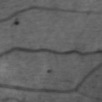

In [5]:
im_an = data.microaneurysms()
im_an

0.41960784313725474


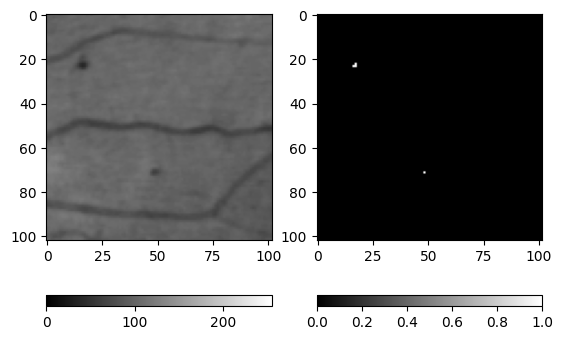

In [9]:
# point detection
k = -1 *np.ones((3, 3))
k[1, 1] = 8

imf = convolve(img_as_float(im_an), k)

print(np.abs(imf).max()
)
imp = np.abs(imf) > 0.9 * np.abs(imf).max()


fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im_an, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imp, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

# Line detection

[[ 2. -1. -1.]
 [-1.  2. -1.]
 [-1. -1.  2.]]


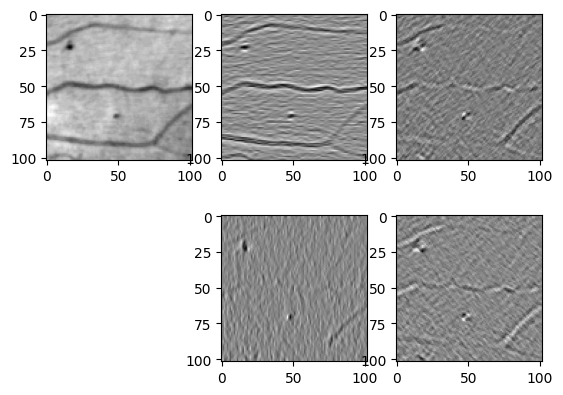

In [16]:
# line detection

k = -1 * np.ones((3,3))

# row 1 filled with 2
k0 = k.copy()
k0[1,:] = 2

# column 1 filled with 2
k2 = k.copy()
k2[:,1] = 2

# diagonal filled with 2 [+45 degree]
k3 = k.copy()
np.fill_diagonal(k3, 2)
print(k3)

# diagonal filled with 2 [-45 degree]
k1 = k3.copy()
k1 = np.fliplr(k1)

imf0 = convolve(img_as_float(im_an), k0)
imf1 = convolve(img_as_float(im_an), k1)
imf2 = convolve(img_as_float(im_an), k2)
imf3 = convolve(img_as_float(im_an), k3)

fig = plt.figure()
ax = fig.add_subplot(2, 3, 1)
p = plt.imshow(im_an, cmap='gray')
ax = fig.add_subplot(2, 3, 2)
p = plt.imshow(imf0, cmap='gray')
ax = fig.add_subplot(2, 3, 3)
p = plt.imshow(imf1, cmap='gray')
ax = fig.add_subplot(2, 3, 5)
p = plt.imshow(imf2, cmap='gray')
ax = fig.add_subplot(2, 3, 6)
p = plt.imshow(imf3, cmap='gray')

# Edge detection

In [19]:
im_cam = data.camera()

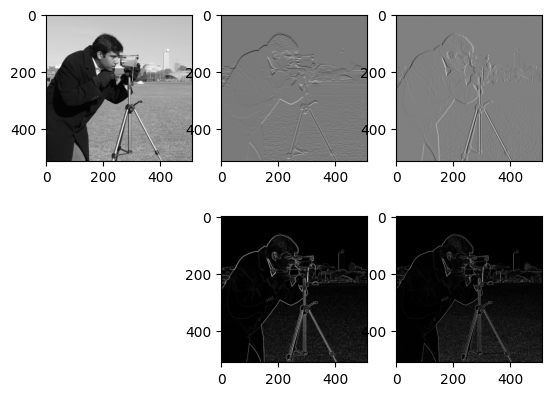

In [23]:
imgx = sobel_h(im_cam)
imgy = sobel_v(im_cam)
img = sobel(im_cam)

imgr = roberts(im_cam) # more sensitive to noise

fig = plt.figure()

ax = fig.add_subplot(2, 3, 1)
p = plt.imshow(im_cam, cmap='gray')

ax = fig.add_subplot(2, 3, 2)
p = plt.imshow(imgx, cmap='gray')

ax = fig.add_subplot(2, 3, 3)
p = plt.imshow(imgy, cmap='gray')

ax = fig.add_subplot(2, 3, 5)
p = plt.imshow(img, cmap='gray')

ax = fig.add_subplot(2, 3, 6)
p = plt.imshow(imgr, cmap='gray')

# Edge detection - Laplacian

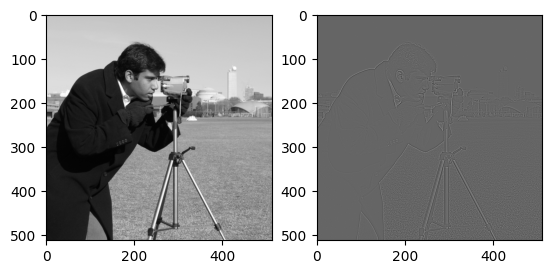

In [26]:
iml = laplace(im_cam)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im_cam, cmap='gray')

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(iml, cmap='gray')

# Basic Threshold

109.90892803308114
103.91077900336374
103.06821079371024
103.06821079371024


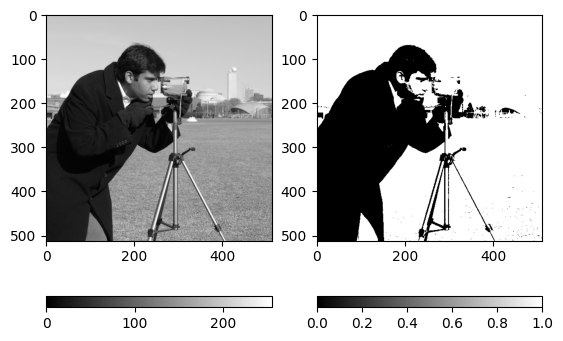

In [30]:
im = data.camera()

v = np.concatenate(im)

# iterative global thresholding algorithm
t = v.mean()
d = np.inf
ds = 0.1

while d > ds:
  g1 = v[v>t]
  g2 = v[v<=t]
  m1 = g1.mean()
  m2 = g2.mean()

  tp = (m1 + m2)/2
  d = np.abs(t - tp)
  t = tp
  print(t)

imt = im > t

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imt, cmap='gray')
c = plt.colorbar(orientation='horizontal')

# Threshold

102


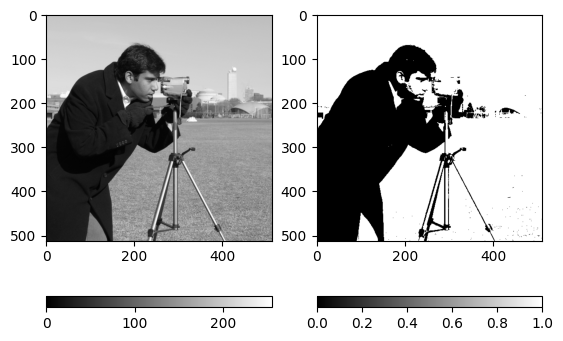

In [31]:
im = data.camera()

#Otsu's global thresholding algorithm
t = threshold_otsu(im)
print(t)
imt = im > t

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imt, cmap='gray')
c = plt.colorbar(orientation='horizontal')

# Region growing

In [33]:
def get8n(x, y, shape):
  out = []
  maxx = shape[1]-1
  maxy = shape[0]-1

  #top left
  outx = min(max(x-1,0),maxx)
  outy = min(max(y-1,0),maxy)
  out.append((outx,outy))

  #top center
  outx = x
  outy = min(max(y-1,0),maxy)
  out.append((outx,outy))

  #top right
  outx = min(max(x+1,0),maxx)
  outy = min(max(y-1,0),maxy)
  out.append((outx,outy))

  #left
  outx = min(max(x-1,0),maxx)
  outy = y
  out.append((outx,outy))

  #right
  outx = min(max(x+1,0),maxx)
  outy = y
  out.append((outx,outy))

  #bottom left
  outx = min(max(x-1,0),maxx)
  outy = min(max(y+1,0),maxy)
  out.append((outx,outy))

  #bottom center
  outx = x
  outy = min(max(y+1,0),maxy)
  out.append((outx,outy))

  #bottom right
  outx = min(max(x+1,0),maxx)
  outy = min(max(y+1,0),maxy)
  out.append((outx,outy))

  return out

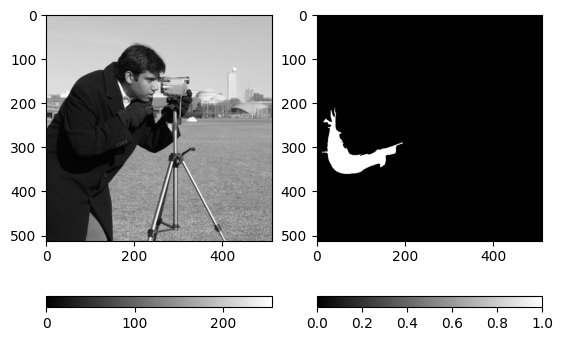

In [34]:
im = data.camera()

t = threshold_otsu(im) * 0.15

x0 = 321
y0 = 128
coords = []
processed = []
coords.append((x0, y0))
imtr = np.zeros_like(im>0)
while(len(coords) > 0):
  pix = coords[0]
  imtr[pix[0], pix[1]] = 1
  for pix8n in get8n(pix[0], pix[1], im.shape):
    if im[pix8n[0], pix8n[1]] < t:
      imtr[pix8n[0], pix8n[1]] = 1
      if not pix8n in processed:
        coords.append(pix8n)
      processed.append(pix8n)
  coords.pop(0)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imtr, cmap='gray')
c = plt.colorbar(orientation='horizontal')